<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/Gene%20expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Employee Shift Preferences
Employee 1: Night
Employee 2: Morning
Employee 3: Night
Employee 4: Night
Employee 5: Morning
Employee 6: Morning
Employee 7: Night
Employee 8: Evening
Employee 9: Night
Employee 10: Night
Generation 1: Best Fitness = 290.80
Generation 2: Best Fitness = 290.80
Generation 3: Best Fitness = 200.80
Generation 4: Best Fitness = 200.80
Generation 5: Best Fitness = 200.80
Generation 6: Best Fitness = 200.80
Generation 7: Best Fitness = 200.80
Generation 8: Best Fitness = 140.80
Generation 9: Best Fitness = 100.80
Generation 10: Best Fitness = 100.80
Generation 11: Best Fitness = 100.80
Generation 12: Best Fitness = 100.80
Generation 13: Best Fitness = 100.80
Generation 14: Best Fitness = 100.80
Generation 15: Best Fitness = 100.80
Generation 16: Best Fitness = 100.80
Generation 17: Best Fitness = 100.80
Generation 18: Best Fitness = 100.80
Generation 19: Best Fitness = 100.80
Generation 20: Best Fitness = 100.80
Generation 21: Best Fitness = 100.80
Generation 22: B

,Day,Morning,Evening,Night
0,Monday,"Employee 2, Employee 5","Employee 8, Employee 3","Employee 1, Employee 4"
1,Tuesday,"Employee 6, Employee 2","Employee 8, Employee 7","Employee 9, Employee 10"
2,Wednesday,"Employee 5, Employee 6","Employee 3, Employee 8","Employee 1, Employee 4"
3,Thursday,"Employee 2, Employee 5","Employee 7, Employee 8","Employee 10, Employee 9"
4,Friday,"Employee 6, Employee 2","Employee 1, Employee 3","Employee 4, Employee 7"
5,Saturday,"Employee 5, Employee 6","Employee 4, Employee 3","Employee 9, Employee 10"
6,Sunday,"Employee 5, Employee 7","Employee 8, Employee 10","Employee 9, Employee 1"


,Employee,Weekly Shifts
0,Employee 1,4
1,Employee 2,4
2,Employee 3,4
3,Employee 4,4
4,Employee 5,5
5,Employee 6,4
6,Employee 7,4
7,Employee 8,5
8,Employee 9,4
9,Employee 10,4


Best Fitness: 100.8
Total Assignments: 42
Preference Violations: 10
Workload Violations: 0
Daily Conflicts: 0
Every Shift Has Two Employees: True
No Daily Scheduling Conflicts: True
All Employees Have 4-5 Shifts: True


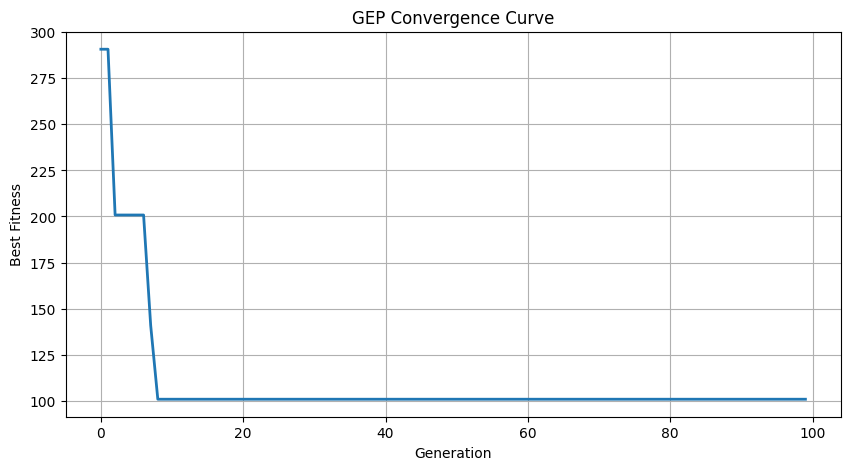

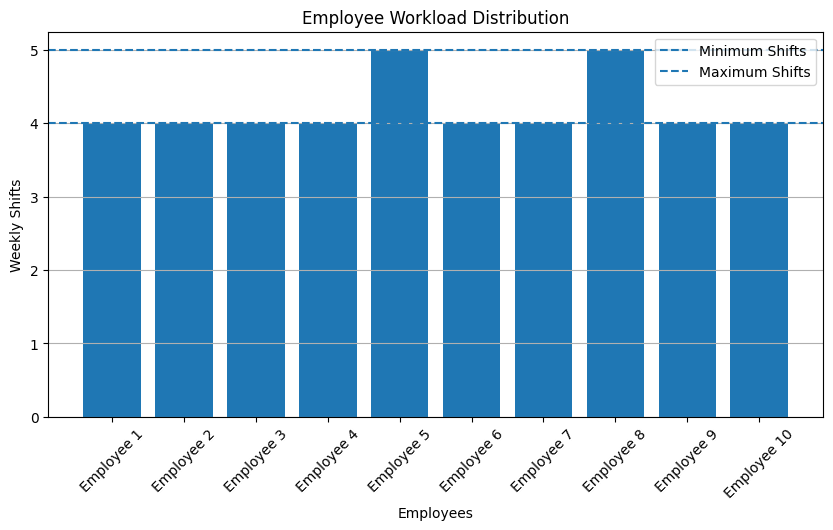

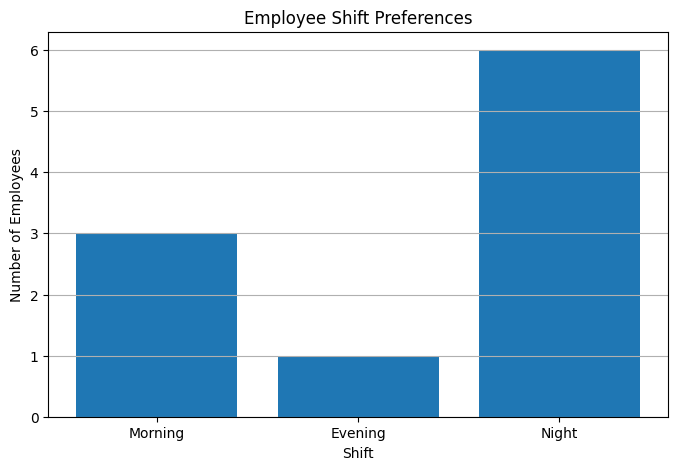

Excel file generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from scipy.optimize import linear_sum_assignment
from IPython.display import display

NUM_EMPLOYEES = 10
NUM_DAYS = 7
NUM_SHIFTS = 3
EMPLOYEES_PER_SHIFT = 2
MIN_SHIFTS = 4
MAX_SHIFTS = 5

POPULATION_SIZE = 50
GENERATIONS = 100
HEAD_LENGTH = 8
CROSSOVER_RATE = 0.7
MUTATION_RATE = 0.08
ELITE_SIZE = 2

np.random.seed(42)
random.seed(42)

days = ["Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"]

shifts = ["Morning", "Evening", "Night"]

NUM_SLOTS = NUM_SHIFTS * EMPLOYEES_PER_SHIFT
MAX_ARITY = 2
TAIL_LENGTH = HEAD_LENGTH * (MAX_ARITY - 1) + 1

FUNCTIONS = ["add", "sub", "mul", "div", "max", "min", "abs"]

TERMINALS = ["p", "n", "l", "s", "one", "zero"]

ALL_SYMBOLS = FUNCTIONS + TERMINALS

ARITY = {
    "add": 2,
    "sub": 2,
    "mul": 2,
    "div": 2,
    "max": 2,
    "min": 2,
    "abs": 1
}

employee_preferences = np.random.randint(
    0, NUM_SHIFTS, NUM_EMPLOYEES
)

print("Employee Shift Preferences")

for i in range(NUM_EMPLOYEES):
    print(f"Employee {i+1}: {shifts[employee_preferences[i]]}")


def create_chromosome():

    head = [
        random.choice(ALL_SYMBOLS)
        for _ in range(HEAD_LENGTH)
    ]

    tail = [
        random.choice(TERMINALS)
        for _ in range(TAIL_LENGTH)
    ]

    return head + tail


def build_expression(chromosome):

    position = [0]

    def parse():

        symbol = chromosome[position[0]]
        position[0] += 1

        if symbol in ARITY:
            children = [
                parse() for _ in range(ARITY[symbol])
            ]
            return (symbol, children)

        return symbol

    return parse()


def evaluate_expression(tree, features):

    if isinstance(tree, str):

        if tree == "one":
            return np.ones_like(features["p"])

        if tree == "zero":
            return np.zeros_like(features["p"])

        return features[tree]

    operation, children = tree

    values = [
        evaluate_expression(child, features)
        for child in children
    ]

    if operation == "add":
        result = values[0] + values[1]

    elif operation == "sub":
        result = values[0] - values[1]

    elif operation == "mul":
        result = values[0] * values[1]

    elif operation == "div":
        result = values[0] / np.where(
            np.abs(values[1]) < 0.001,
            0.001,
            values[1]
        )

    elif operation == "max":
        result = np.maximum(values[0], values[1])

    elif operation == "min":
        result = np.minimum(values[0], values[1])

    elif operation == "abs":
        result = np.abs(values[0])

    return np.clip(
        np.nan_to_num(result, nan=0.0, posinf=10, neginf=-10),
        -10,
        10
    )


def decode_chromosome(chromosome):

    tree = build_expression(chromosome)

    schedule = np.zeros(
        (NUM_DAYS, NUM_SHIFTS, EMPLOYEES_PER_SHIFT),
        dtype=int
    )

    workload = np.zeros(NUM_EMPLOYEES)

    for day in range(NUM_DAYS):

        shift_indices = np.repeat(
            np.arange(NUM_SHIFTS),
            EMPLOYEES_PER_SHIFT
        )

        preference_match = (
            employee_preferences[None, :] ==
            shift_indices[:, None]
        ).astype(float)

        workload_need = np.tile(
            ((4.2 - workload) / 5),
            (NUM_SLOTS, 1)
        )

        lower_workload = np.tile(
            ((5 - workload) / 5),
            (NUM_SLOTS, 1)
        )

        shift_feature = np.tile(
            (shift_indices / 2)[:, None],
            (1, NUM_EMPLOYEES)
        )

        features = {
            "p": preference_match,
            "n": workload_need,
            "l": lower_workload,
            "s": shift_feature
        }

        scores = evaluate_expression(tree, features)

        rows, cols = linear_sum_assignment(-scores)

        for row, col in zip(rows, cols):

            shift = row // EMPLOYEES_PER_SHIFT
            slot = row % EMPLOYEES_PER_SHIFT

            schedule[day, shift, slot] = col
            workload[col] += 1

    return schedule


def fitness_function(chromosome):

    schedule = decode_chromosome(chromosome)

    workload = np.zeros(NUM_EMPLOYEES)
    preference_penalty = 0

    for day in range(NUM_DAYS):

        for shift in range(NUM_SHIFTS):

            for emp in schedule[day, shift]:

                workload[emp] += 1

                if employee_preferences[emp] != shift:
                    preference_penalty += 1

    workload_penalty = np.sum(
        np.maximum(MIN_SHIFTS - workload, 0) +
        np.maximum(workload - MAX_SHIFTS, 0)
    )

    fairness_penalty = np.var(workload)

    fitness = (
        1000 * workload_penalty +
        10 * preference_penalty +
        5 * fairness_penalty
    )

    return fitness


def mutate(chromosome):

    new_chromosome = chromosome.copy()

    for i in range(len(new_chromosome)):

        if random.random() < MUTATION_RATE:

            if i < HEAD_LENGTH:
                new_chromosome[i] = random.choice(ALL_SYMBOLS)
            else:
                new_chromosome[i] = random.choice(TERMINALS)

    return new_chromosome


def crossover(parent1, parent2):

    point = random.randint(1, len(parent1) - 1)

    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]

    return child1, child2


def tournament_selection(population, fitness_values):

    selected = random.sample(
        range(len(population)),
        3
    )

    winner = min(
        selected,
        key=lambda i: fitness_values[i]
    )

    return population[winner].copy()


population = [
    create_chromosome()
    for _ in range(POPULATION_SIZE)
]

fitness_values = [
    fitness_function(chromosome)
    for chromosome in population
]

best_history = []

best_index = np.argmin(fitness_values)

global_best = population[best_index].copy()
global_best_fitness = fitness_values[best_index]

for generation in range(GENERATIONS):

    sorted_indices = np.argsort(fitness_values)

    new_population = [
        population[i].copy()
        for i in sorted_indices[:ELITE_SIZE]
    ]

    while len(new_population) < POPULATION_SIZE:

        parent1 = tournament_selection(
            population, fitness_values
        )

        parent2 = tournament_selection(
            population, fitness_values
        )

        if random.random() < CROSSOVER_RATE:

            child1, child2 = crossover(parent1, parent2)

        else:

            child1 = parent1.copy()
            child2 = parent2.copy()

        child1 = mutate(child1)
        child2 = mutate(child2)

        new_population.append(child1)

        if len(new_population) < POPULATION_SIZE:
            new_population.append(child2)

    population = new_population

    fitness_values = [
        fitness_function(chromosome)
        for chromosome in population
    ]

    generation_best_index = np.argmin(fitness_values)

    generation_best_fitness = fitness_values[
        generation_best_index
    ]

    if generation_best_fitness < global_best_fitness:

        global_best_fitness = generation_best_fitness

        global_best = population[
            generation_best_index
        ].copy()

    best_history.append(global_best_fitness)

    print(
        f"Generation {generation+1}: "
        f"Best Fitness = {global_best_fitness:.2f}"
    )


best_schedule = decode_chromosome(global_best)

workload = np.zeros(NUM_EMPLOYEES, dtype=int)

for day in range(NUM_DAYS):
    for shift in range(NUM_SHIFTS):
        for emp in best_schedule[day, shift]:
            workload[emp] += 1


schedule_data = []

for day in range(NUM_DAYS):

    row = {"Day": days[day]}

    for shift in range(NUM_SHIFTS):

        row[shifts[shift]] = ", ".join(
            f"Employee {emp+1}"
            for emp in best_schedule[day, shift]
        )

    schedule_data.append(row)

schedule_df = pd.DataFrame(schedule_data)

workload_df = pd.DataFrame({
    "Employee": [
        f"Employee {i+1}"
        for i in range(NUM_EMPLOYEES)
    ],
    "Weekly Shifts": workload
})

display(schedule_df)
display(workload_df)


preference_violations = 0

for day in range(NUM_DAYS):
    for shift in range(NUM_SHIFTS):
        for emp in best_schedule[day, shift]:
            if employee_preferences[emp] != shift:
                preference_violations += 1

workload_violations = np.sum(
    (workload < MIN_SHIFTS) |
    (workload > MAX_SHIFTS)
)

daily_conflicts = 0

for day in range(NUM_DAYS):

    assigned = best_schedule[day].flatten()

    daily_conflicts += (
        len(assigned) - len(set(assigned))
    )

print("Best Fitness:", round(global_best_fitness, 2))
print("Total Assignments:", workload.sum())
print("Preference Violations:", preference_violations)
print("Workload Violations:", workload_violations)
print("Daily Conflicts:", daily_conflicts)

print(
    "Every Shift Has Two Employees:",
    best_schedule.shape == (7, 3, 2)
)

print(
    "No Daily Scheduling Conflicts:",
    daily_conflicts == 0
)

print(
    "All Employees Have 4-5 Shifts:",
    workload_violations == 0
)


plt.figure(figsize=(10, 5))
plt.plot(best_history, linewidth=2)
plt.title("GEP Convergence Curve")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))
plt.bar(
    workload_df["Employee"],
    workload_df["Weekly Shifts"]
)
plt.axhline(MIN_SHIFTS, linestyle="--", label="Minimum Shifts")
plt.axhline(MAX_SHIFTS, linestyle="--", label="Maximum Shifts")
plt.title("Employee Workload Distribution")
plt.xlabel("Employees")
plt.ylabel("Weekly Shifts")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y")
plt.show()


plt.figure(figsize=(8, 5))

preference_counts = [
    np.sum(employee_preferences == i)
    for i in range(NUM_SHIFTS)
]

plt.bar(shifts, preference_counts)
plt.title("Employee Shift Preferences")
plt.xlabel("Shift")
plt.ylabel("Number of Employees")
plt.grid(axis="y")
plt.show()


with pd.ExcelWriter("GEP_Employee_Scheduling.xlsx") as writer:

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Schedule",
        index=False
    )

    workload_df.to_excel(
        writer,
        sheet_name="Employee Workload",
        index=False
    )

    pd.DataFrame({
        "Generation": range(1, GENERATIONS + 1),
        "Best Fitness": best_history
    }).to_excel(
        writer,
        sheet_name="Convergence",
        index=False
    )

    pd.DataFrame({
        "Employee": [
            f"Employee {i+1}"
            for i in range(NUM_EMPLOYEES)
        ],
        "Preferred Shift": [
            shifts[p]
            for p in employee_preferences
        ]
    }).to_excel(
        writer,
        sheet_name="Preferences",
        index=False
    )

    pd.DataFrame({
        "Gene Position": range(1, len(global_best) + 1),
        "Gene": global_best
    }).to_excel(
        writer,
        sheet_name="Best Chromosome",
        index=False
    )

print("Excel file generated successfully!")

from google.colab import files
files.download("GEP_Employee_Scheduling.xlsx")
